<a href="https://colab.research.google.com/github/IvanZinchenko3214/dap-2024/blob/main/les08/rep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

print(f"Python version: {sys.version}")
print(f"Numpy version: {np.version.version}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {mpl.__version__}")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Numpy version: 2.4.6
Pandas version: 2.2.3
Matplotlib version: 3.10.0


In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
X = iris.data
y_true = iris.target

In [3]:
print("\nПервые 5 строк набора данных:")
print(df.head())


Первые 5 строк набора данных:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
cluster_labels = dbscan.fit_predict(X_scaled)

In [6]:
df['cluster'] = cluster_labels

In [7]:
print("\nРаспределение точек по кластерам:")
print(df['cluster'].value_counts().sort_index())


Распределение точек по кластерам:
cluster
-1    34
 0    45
 1    71
Name: count, dtype: int64


In [8]:
plt.figure(figsize=(8, 6))

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

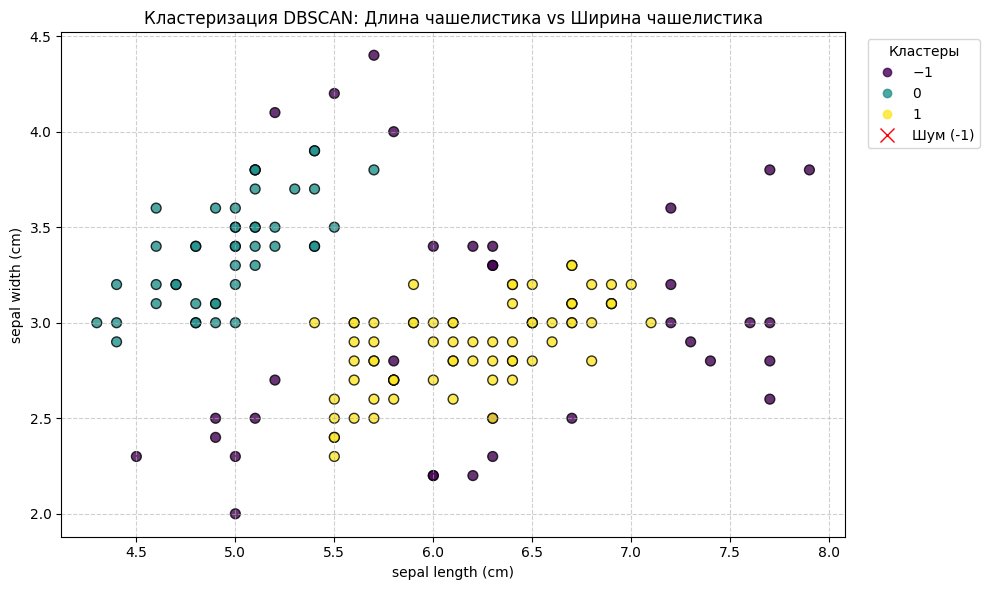

In [14]:
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df['sepal length (cm)'],
    df['sepal width (cm)'],
    c=df['cluster'],
    cmap='viridis',
    edgecolor='k',
    s=50,
    alpha=0.8
)

plt.title('Кластеризация DBSCAN: Длина чашелистика vs Ширина чашелистика')
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')
plt.grid(True, linestyle='--', alpha=0.6)

handles, labels = scatter.legend_elements()

if -1 in df['cluster'].values:
    noise_marker = mlines.Line2D(
        [], [], color='red', marker='x', linestyle='None',
        markersize=10, label='Шум (-1)'
    )
    handles.append(noise_marker)
    labels.append('Шум (-1)')

legend = plt.legend(
    handles, labels,
    title="Кластеры",
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    borderaxespad=0.5,
    frameon=True
)

plt.tight_layout()
plt.show()

In [13]:
print("\n--- Вывод ---")
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = list(cluster_labels).count(-1)

print(f"1. Алгоритм DBSCAN нашел {n_clusters} кластеров и определил {n_noise} точек как шум (выбросы).")
print("2. На диаграмме рассеяния видно, что DBSCAN успешно выделил один компактный кластер (обычно это вид Iris-Setosa, ")
print("   который имеет наименьшую ширину чашелистика при большой длине).")
print("3. Остальные два вида (Iris-Versicolor и Iris-Virginica) в пространстве этих двух признаков сильно перекрываются.")
print("   DBSCAN либо объединяет их в один крупный кластер, либо помечает точки на границе пересечения как 'шум' (-1),")
print("   что является особенностью алгоритма, чувствительного к плотности.")
print("4. В отличие от K-Means, DBSCAN не заставляет каждую точку принадлежать кластеру, что делает его более robust")
print("   к выбросам, но он может хуже справляться с данными, где кластеры имеют сильно различающуюся плотность.")


--- Вывод ---
1. Алгоритм DBSCAN нашел 2 кластеров и определил 34 точек как шум (выбросы).
2. На диаграмме рассеяния видно, что DBSCAN успешно выделил один компактный кластер (обычно это вид Iris-Setosa, 
   который имеет наименьшую ширину чашелистика при большой длине).
3. Остальные два вида (Iris-Versicolor и Iris-Virginica) в пространстве этих двух признаков сильно перекрываются.
   DBSCAN либо объединяет их в один крупный кластер, либо помечает точки на границе пересечения как 'шум' (-1),
   что является особенностью алгоритма, чувствительного к плотности.
4. В отличие от K-Means, DBSCAN не заставляет каждую точку принадлежать кластеру, что делает его более robust
   к выбросам, но он может хуже справляться с данными, где кластеры имеют сильно различающуюся плотность.
